# Wind speed forecasting – Tibau (Brazil)

Goal: predict the next hour's wind speed from the previous 24 hours, using an LSTM.
Data: hourly wind speed (m/s) and direction (°) for Tibau, from March 2020 onwards.

I also compare against a naive "persistence" forecast (next hour = this hour), because
for hourly wind that baseline is surprisingly hard to beat and it tells you whether the
network actually learned anything.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

## Load & clean

In [2]:
df = pd.read_csv("tibau_wind_data.csv", header=None,
                 names=["timestamp", "speed", "direction"],
                 parse_dates=["timestamp"], index_col="timestamp")

print(df.shape)
print(df.isna().sum())
df.head()

(10681, 2)
speed        0
direction    0
dtype: int64


,speed,direction
timestamp,,
2020-03-12 12:00:00,6.78,90.02
2020-03-12 13:00:00,6.78,90.02
2020-03-12 14:00:00,6.78,90.02
2020-03-12 15:00:00,6.78,90.02
2020-03-12 16:00:00,6.78,90.02


In [3]:
# A few gaps in the record - forward fill is fine for hourly met data
df = df.asfreq("h").ffill()

# direction is circular (359° is next to 1°), so split it into sin/cos
rad = np.deg2rad(df["direction"])
df["dir_sin"] = np.sin(rad)
df["dir_cos"] = np.cos(rad)

# hour of day as sin/cos too - wind here has a strong daily cycle
df["hour_sin"] = np.sin(2 * np.pi * df.index.hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * df.index.hour / 24)

feature_cols = ["speed", "dir_sin", "dir_cos", "hour_sin", "hour_cos"]

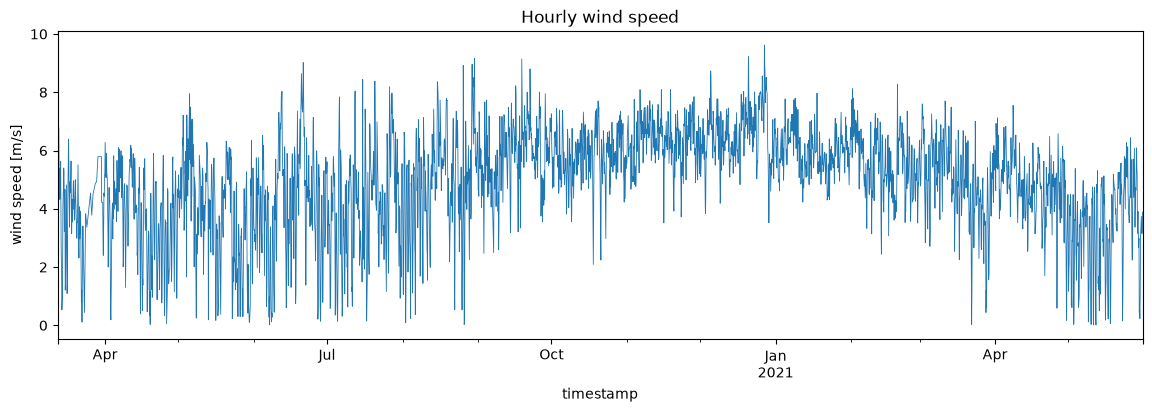

In [4]:
fig, ax = plt.subplots(figsize=(14, 4))
df["speed"].plot(ax=ax, lw=0.6)
ax.set_ylabel("wind speed [m/s]")
ax.set_title("Hourly wind speed")
plt.show()

## Train / val / test split

Chronological 70/15/15. The scaler is fitted on the training part only -
fitting on the whole series would leak information about the test period.

In [5]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

scaler = MinMaxScaler()
scaler.fit(df.iloc[:train_end][feature_cols])
scaled = scaler.transform(df[feature_cols])

# speed is column 0, keep its min/max to convert predictions back to m/s
spd_min, spd_max = scaler.data_min_[0], scaler.data_max_[0]
def to_ms(x):
    return np.asarray(x).ravel() * (spd_max - spd_min) + spd_min

In [6]:
LOOKBACK = 24  # hours of history the model sees

def make_windows(data, start, end, lookback=LOOKBACK):
    X, y = [], []
    for t in range(max(start, lookback), end):
        X.append(data[t - lookback:t])
        y.append(data[t, 0])
    return np.array(X), np.array(y)

X_train, y_train = make_windows(scaled, 0, train_end)
X_val, y_val = make_windows(scaled, train_end, val_end)
X_test, y_test = make_windows(scaled, val_end, n)
print(X_train.shape, X_val.shape, X_test.shape)

(7452, 24, 5) (1602, 24, 5) (1603, 24, 5)


## Model

In [7]:
model = keras.Sequential([
    layers.Input(shape=(LOOKBACK, len(feature_cols))),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),
    layers.Dense(1),
])
model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,369 (118.63 KB)

 Trainable params: 30,369 (118.63 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stop = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=50, batch_size=64, callbacks=[early_stop], verbose=2)

Epoch 1/50


117/117 - 10s - 86ms/step - loss: 0.0260 - val_loss: 0.0059


Epoch 2/50


117/117 - 5s - 40ms/step - loss: 0.0104 - val_loss: 0.0049


Epoch 3/50


117/117 - 5s - 41ms/step - loss: 0.0079 - val_loss: 0.0040


... (38 outputs left out)

Epoch 23/50


117/117 - 5s - 41ms/step - loss: 8.8991e-04 - val_loss: 8.1462e-04


Epoch 24/50


117/117 - 5s - 41ms/step - loss: 9.5318e-04 - val_loss: 5.0239e-04


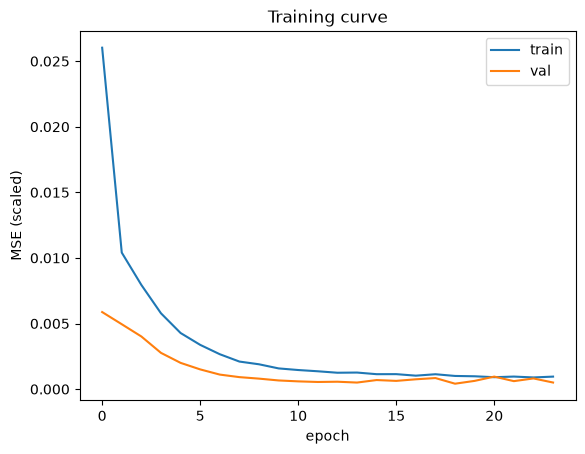

In [9]:
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("MSE (scaled)")
plt.legend(); plt.title("Training curve")
plt.show()

## Evaluation on the test period

In [10]:
y_true = to_ms(y_test)
y_lstm = to_ms(model.predict(X_test, verbose=0))
y_persist = to_ms(X_test[:, -1, 0])  # last observed speed

def report(name, pred):
    mae = mean_absolute_error(y_true, pred)
    rmse = np.sqrt(mean_squared_error(y_true, pred))
    print(f"{name:<12} MAE {mae:.3f} m/s   RMSE {rmse:.3f} m/s")
    return mae, rmse

report("Persistence", y_persist)
report("LSTM", y_lstm)

Persistence  MAE 0.251 m/s   RMSE 0.333 m/s
LSTM         MAE 0.160 m/s   RMSE 0.215 m/s


(0.15963662154177763, np.float64(0.2149304489978612))

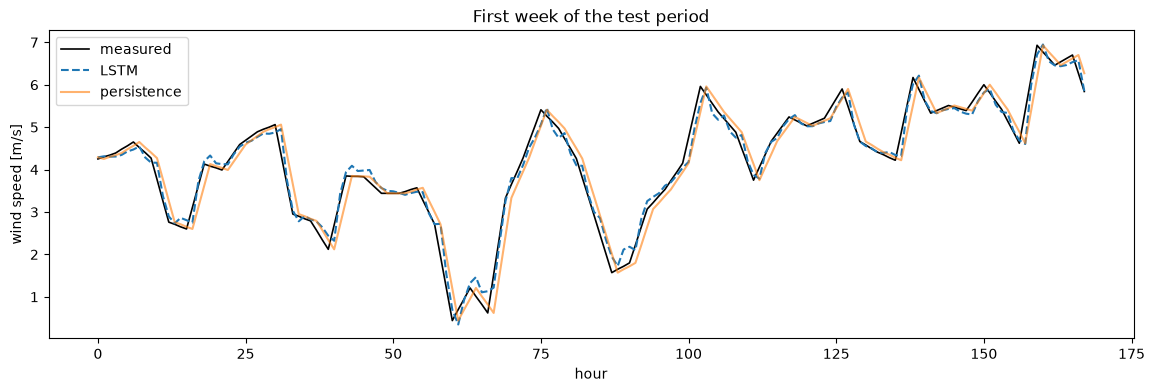

In [11]:
week = slice(0, 24 * 7)
plt.figure(figsize=(14, 4))
plt.plot(y_true[week], label="measured", color="black", lw=1.2)
plt.plot(y_lstm[week], label="LSTM", ls="--")
plt.plot(y_persist[week], label="persistence", alpha=0.6)
plt.ylabel("wind speed [m/s]"); plt.xlabel("hour")
plt.title("First week of the test period")
plt.legend()
plt.show()

## Notes

- At a 1-hour horizon persistence is a strong baseline, so the LSTM's gain is modest.
  The gap should widen for longer horizons (6-24 h ahead) – that's the next thing I'd try.
- Converting wind speed to power would need the turbine power curve (roughly ∝ v³ between cut-in and rated speed).